In [1]:
%pip show numpy


Name: numpy
Version: 2.5.4
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License-Expression: BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0
Location: C:\Users\ompra\PycharmProjects\JupyterProject\.venv\Lib\site-packages
Requires: 
Required-by: contourpy, matplotlib, pandas
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_csv("Telco_Customer_Churn_Dataset (cleaned).csv")




In [7]:
print("Dataset loaded successfully")

Dataset loaded successfully


In [8]:
df.shape

(7043, 21)

In [9]:
df.dtypes

customer_id              str
gender                   str
senior_citizen         int64
partner                  str
dependents               str
tenure                 int64
phone_service            str
multiple_lines           str
internet_service         str
online_security          str
online_backup            str
device_protection        str
tech_support             str
streaming_tv             str
streaming_movies         str
contract                 str
paperless_billing        str
payment_method           str
monthly_charges      float64
total_charges        float64
churn                    str
dtype: object

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Telco_Customer_Churn_Dataset (cleaned).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [11]:
numerical_columns = [
    "tenure",
    "monthly_charges",
    "total_charges"
]

df[numerical_columns].head()

,tenure,monthly_charges,total_charges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


In [15]:
df[numerical_columns].mean()

tenure               32.371149
monthly_charges      64.761692
total_charges      2279.734304
dtype: float64

In [16]:
df[numerical_columns].median()

tenure               29.00
monthly_charges      70.35
total_charges      1394.55
dtype: float64

In [17]:
df[numerical_columns].mode()

,tenure,monthly_charges,total_charges
0,1.0,20.05,0.0
1,NaN,NaN,20.2


In [18]:
summary = df[numerical_columns].agg(
    ["mean", "median", "std", "min", "max"]
)

summary

,tenure,monthly_charges,total_charges
mean,32.371149,64.761692,2279.734304
median,29.000000,70.350000,1394.550000
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
max,72.000000,118.750000,8684.800000



## 3.1 Summary Statistical Analysis

Summary statistics were calculated for three numerical variables: tenure, monthly_charges, and total_charges.

### Key Findings

**1. Customer Tenure**
- Average tenure: 32.37 months.
- Median tenure: 29 months.
- Customers show considerable variation in their relationship duration.

**2. Monthly Charges**
- Average monthly charges: $64.76.
- Median monthly charges: $70.35.
- Monthly spending varies considerably across customers.

**3. Total Charges**
- Average total charges: $2,279.73.
- Median total charges: $1,394.55.
- The difference between mean and median suggests a right-skewed distribution.

### Conclusion

The statistical analysis reveals considerable variation in customer tenure and spending behaviour. These findings provide an initial understanding of the customer base and establish a foundation for further exploratory analysis.


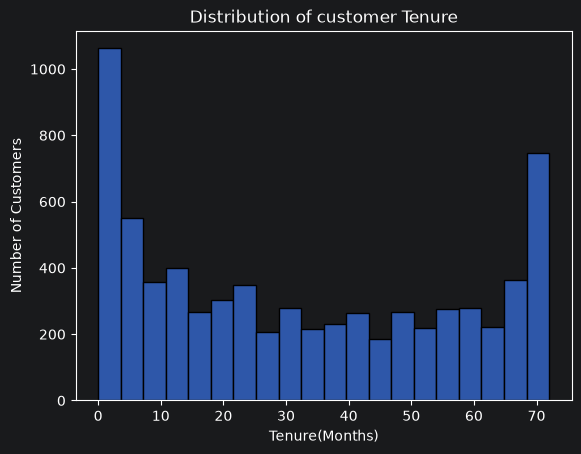

In [19]:
sns.histplot(data=df, x="tenure", bins=20)

plt.title("Distribution of customer Tenure")
plt.xlabel("Tenure(Months)")
plt.ylabel("Number of Customers")

plt.show()

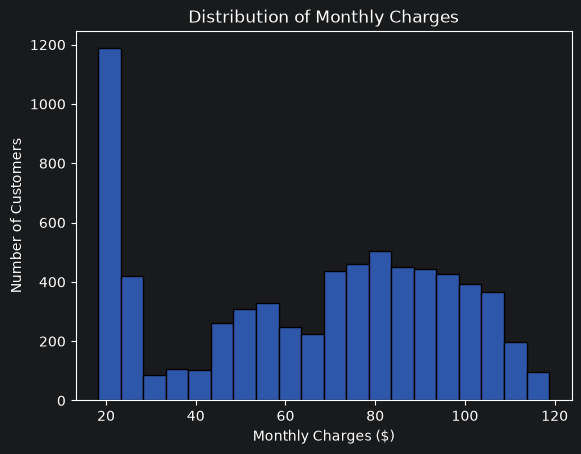

In [20]:
sns.histplot(data=df, x="monthly_charges", bins=20)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Number of Customers")

plt.show()

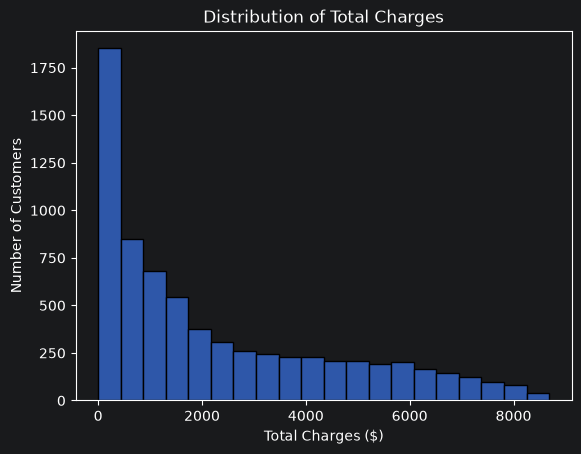

In [21]:
sns.histplot(data=df, x="total_charges", bins=20)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges ($)")
plt.ylabel("Number of Customers")

plt.show()

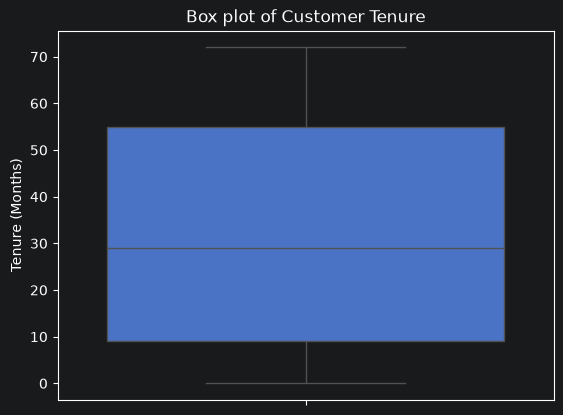

In [22]:
sns.boxplot(y=df["tenure"])

plt.title("Box plot of Customer Tenure")
plt.ylabel("Tenure (Months)")

plt.show()

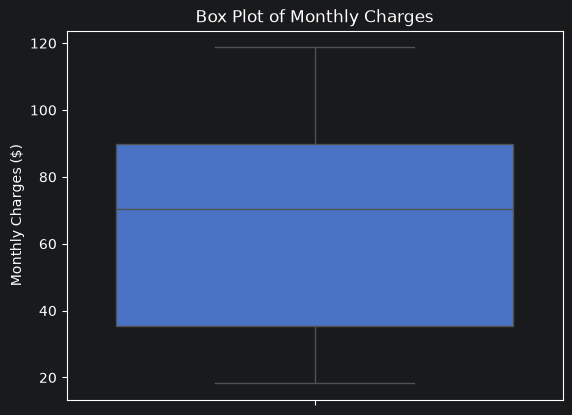

In [23]:
sns.boxplot(y=df["monthly_charges"])

plt.title("Box Plot of Monthly Charges")
plt.ylabel("Monthly Charges ($)")
plt.show()

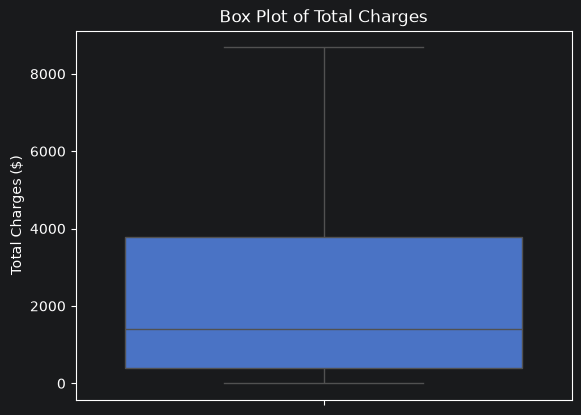

In [24]:
sns.boxplot(y=df["total_charges"])

plt.title("Box Plot of Total Charges")
plt.ylabel("Total Charges ($)")
plt.show()

### Box Plot Analysis – Total Charges

The box plot illustrates the distribution of total charges
among customers.

**Key Observations:**
- The median total charge is approximately $1,394.55.
- The middle 50% of customer spending values show a wide spread.
- The upper portion of the distribution extends considerably
  further than the lower portion.
- This suggests a positively skewed distribution.
- No individual outlier points are visibly displayed in the chart.

**Conclusion:**
Customer total charges vary considerably, indicating
differences in accumulated spending across the customer base.

In [26]:
df["churn"]. value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

In [27]:
df["churn"].value_counts(normalize=True)*100

churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

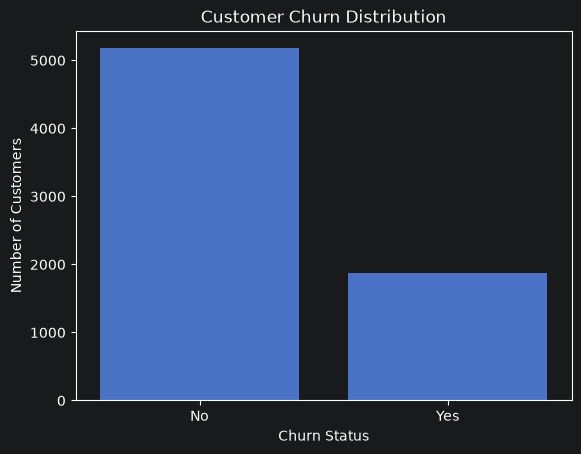

In [28]:
sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [29]:
churn_counts = df["churn"].value_counts()

print(churn_counts)

churn
No     5174
Yes    1869
Name: count, dtype: int64


In [30]:
churn_percentage = (
    df["churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [31]:
churn_rate = (
    df["churn"].eq("Yes").mean() * 100
)

retention_rate = (
    df["churn"].eq("No").mean() * 100
)

print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Churn Rate: 26.54 %
Retention Rate: 73.46 %


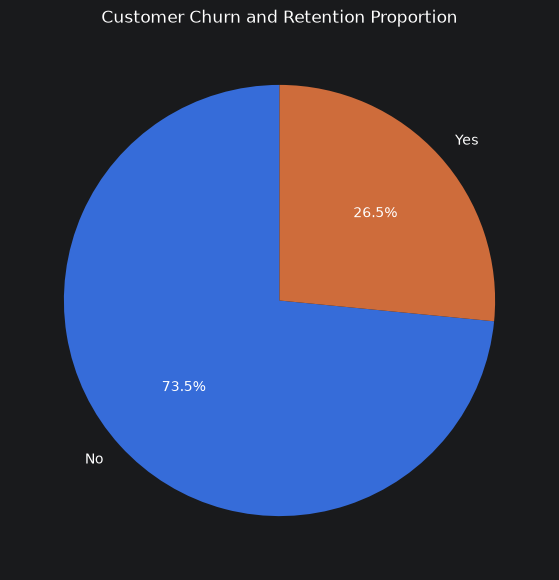

In [32]:
churn_counts = df["churn"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn and Retention Proportion")
plt.show()


### Customer Churn and Retention Analysis

The customer churn distribution was analysed using Pandas and visualised through a pie chart.

**Key Findings:**

- Approximately 26.5% of customers have churned.
- Approximately 73.5% of customers have been retained.
- The majority of customers continue using the company's services.

**Business Interpretation:**

Although the company retains most of its customers, a churn rate of approximately 26.5% indicates a considerable customer-loss problem.

Further investigation is required to identify customer characteristics and service-related patterns associated with higher churn.

**Conclusion:**

The churn analysis establishes a baseline for understanding customer retention and provides direction for further customer segmentation and advanced analysis.
